# M6.1 · 实时行情与信号

> 实盘要在 tick 到达时即时清洗行情、增量更新信号并管理交易时钟。
> 与回测不同，数据是流式到达的，不能每次重算整段历史。

## 一、核心机制

1. **行情清洗**：过滤非正/缺失值与相对上一 tick 跳变超阈值的可疑数据；
2. **增量信号**：维护窗口队列与状态量，新 tick 到达时 O(1) 更新滚动均值/波动，而非重算全窗口；
3. **交易时钟**：判断当前是否在交易时段、计算距收盘时间，用于调度与收尾。

## 二、清洗与增量信号

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np
from live_lab2 import realtime_feed as rf
print('坏值过滤=%s 跳变过滤=%s 正常=%s'
      % (rf.clean_tick(-5), rf.clean_tick(12, 10), rf.clean_tick(10.05, 10)))
im = rf.IncrementalMean(5); iv = rf.IncrementalVolatility(5)
series = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0])
m_path, v_path = [], []
for x in series:
    m_path.append(im.update(x)); v_path.append(iv.update(x))
print('窗口均值路径:', np.round(m_path, 3))
print('窗口波动路径:', np.round(v_path, 3))
clock = rf.TradingClock()
print('10:00 在交易时段=%s，距收盘=%d 分钟' % (clock.in_session('10:00'), clock.minutes_to_close('10:00')))

坏值过滤=None 跳变过滤=None 正常=10.05
窗口均值路径: [1.  1.5 2.  2.5 3.  4.  5. ]
窗口波动路径: [1.    1.581 2.16  2.739 3.317 4.243 5.196]
10:00 在交易时段=True，距收盘=90 分钟


## 三、可视化

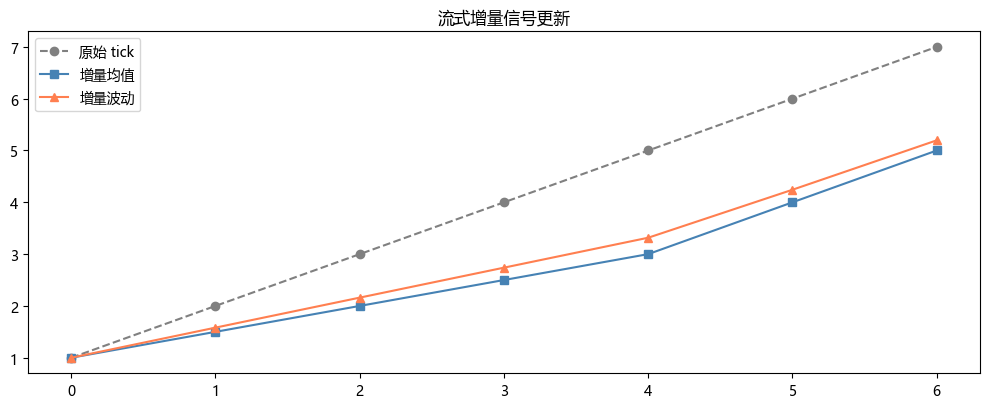

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(series, 'o--', label='原始 tick', color='gray')
ax.plot(m_path, 's-', label='增量均值', color='steelblue')
ax.plot(v_path, '^-', label='增量波动', color='coral')
ax.set_title('流式增量信号更新'); ax.legend()
plt.tight_layout(); plt.show()

## 四、面试要点

- **增量计算相比批量重算的优势？** 每个 tick 只做 O(1) 更新，避免 O(n) 重算整窗口，满足实时低延迟要求。
- **行情清洗要防什么？** 零/负价、缺失、异常跳变（错单或数据错误），坏数据若进入信号会触发错误交易。
- **交易时钟的作用？** 区分交易/非交易时段、控制开盘初始化与收盘收尾、管理午休与节假日。
- **回测与实盘行情接口如何统一？** 抽象成相同的 next/订阅接口，回测喂历史、实盘订阅实时，策略代码不改动。

## 五、练习

1. 实现增量 EWMA 并与全量结果对比。
2. 加入重复时间戳去重逻辑。
3. 扩展时钟支持节假日与半日市。
4. 用真实行情接口替换 MockMarketFeed。